# 05 — Outlier Analysis
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Outlier Analysis and Treatment)

**Project stage:** 5 of 16 — builds on Notebooks 02–04

---

## 1. Objective

This notebook performs a rigorous, business-reasoned outlier investigation across the 12 primary numeric behavioral variables, following one strict rule throughout:

> **Detect → Investigate → Understand the business meaning → Decide a treatment → Apply only what's justified → Compare before vs. after.**

We do **not** delete extreme values just because a statistical rule flags them. A statistical outlier is a candidate for investigation, not an automatic deletion. By the end of this notebook we will have:

1. A full IQR-based outlier summary table (Q1, Q3, IQR, bounds, outlier count/%) for every variable.
2. An honest discussion of where the standard IQR method **breaks down** for this dataset (it does, for several zero-inflated features — shown with real numbers below).
3. A percentile-based and Z-score-based cross-check where IQR is not meaningful.
4. A final Feature → Outlier % → Business Interpretation → Treatment table.
5. Only the small number of clearly justified treatments actually applied, with a before/after comparison.

## 2. Business Context

Throughout Notebooks 02–04 we deliberately deferred several extreme-value questions to this notebook: the `adr` right tail (Notebook 02), zero-night stays (Notebook 02), large guest-party sizes (Notebook 03), and the overall skewed shape of most behavioral features (Notebook 03/04). This is where we finally resolve them, properly.

The stakes are specific to clustering: a single row with an implausible value (for example, a room rate ten times higher than the next most expensive booking in the entire dataset) can pull a cluster centroid toward itself and distort the boundary between segments — even though it represents one booking out of tens of thousands. At the same time, a *legitimate* rare booking (a large family, a very early group booking) is exactly the kind of real behavioral diversity this project exists to find. Getting this distinction right, feature by feature, is the whole point of this notebook.

## 3. Imports

In [1]:
# pandas / numpy: data handling and statistics
import pandas as pd
import numpy as np

# scipy.stats: for Z-score calculation
from scipy import stats

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# os: portable file paths
import os


## 4. Configuration

In [2]:
RANDOM_STATE = 42

CLEANED_DATA_PATH = "../data/processed/02_cleaned_hotel_bookings.csv"

OUTLIER_TREATED_DATA_PATH = "../data/processed/05_outlier_treated_hotel_bookings.csv"
IQR_SUMMARY_PATH = "../reports/tables/05_iqr_outlier_summary.csv"
DECISION_TABLE_PATH = "../reports/tables/05_outlier_treatment_decisions.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(os.path.dirname(OUTLIER_TREATED_DATA_PATH), exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# The 12 numeric variables in scope for outlier analysis.
# Note: is_repeated_guest is intentionally excluded - it is a binary flag,
# and IQR-style outlier analysis is not a meaningful concept for a 0/1 field.
OUTLIER_ANALYSIS_VARS = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "previous_cancellations",
    "previous_bookings_not_canceled",
]

# Audit trail of every treatment actually applied in this notebook.
treatment_log = []

def log_treatment(feature, action, rows_affected, reason):
    treatment_log.append({
        "feature": feature,
        "action": action,
        "rows_affected": rows_affected,
        "reason": reason,
    })


## 5. Analysis / Implementation

### 5.1 Load the Cleaned Data

In [3]:
df = pd.read_csv(CLEANED_DATA_PATH)

print("Loaded shape:", df.shape)


Loaded shape: (87229, 32)


### 5.2 IQR-Based Outlier Detection — Full Summary Table

**What is the IQR method?** The interquartile range (IQR) is the distance between the 25th percentile (Q1) and the 75th percentile (Q3) of a variable — the "middle 50%" of the data. The standard rule flags any value below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` as a statistical outlier. It's a widely used, distribution-agnostic rule of thumb — but as we'll see below, it has a specific, important weakness for data like ours.

In [4]:
def compute_iqr_outlier_summary(data: pd.DataFrame, columns: list) -> pd.DataFrame:
    """
    For each column, compute Q1, Q3, IQR, the lower/upper bounds, and the
    number/percentage of values that fall outside those bounds.
    """
    rows = []

    for column in columns:
        q1 = data[column].quantile(0.25)
        q3 = data[column].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_mask = (data[column] < lower_bound) | (data[column] > upper_bound)
        n_outliers = outlier_mask.sum()
        pct_outliers = round(n_outliers / len(data) * 100, 2)

        rows.append({
            "feature": column,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "n_outliers": n_outliers,
            "pct_outliers": pct_outliers,
        })

    return pd.DataFrame(rows)


iqr_summary = compute_iqr_outlier_summary(df, OUTLIER_ANALYSIS_VARS)
iqr_summary.to_csv(IQR_SUMMARY_PATH, index=False)
iqr_summary


,feature,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,pct_outliers
0,lead_time,11.00,125.0,114.00,-160.000,296.000,2394,2.74
1,stays_in_weekend_nights,0.00,2.0,2.00,-3.000,5.000,213,0.24
2,stays_in_week_nights,1.00,4.0,3.00,-3.500,8.500,1514,1.74
3,adults,2.00,2.0,0.00,2.000,2.000,22733,26.06
4,children,0.00,0.0,0.00,0.000,0.000,8364,9.59
5,babies,0.00,0.0,0.00,0.000,0.000,914,1.05
6,booking_changes,0.00,0.0,0.00,0.000,0.000,15804,18.12
7,adr,72.25,134.1,61.85,-20.525,226.875,2508,2.88
8,required_car_parking_spaces,0.00,0.0,0.00,0.000,0.000,7306,8.38
9,total_of_special_requests,0.00,1.0,1.00,-1.500,2.500,2670,3.06


**What this code does:** applies the standard 1.5×IQR rule to all 12 variables and reports the exact bounds and outlier counts for each.

**What to look for — and the key problem this table reveals:** notice that for several features (`adults`, `children`, `babies`, `booking_changes`, `required_car_parking_spaces`, `previous_cancellations`, `previous_bookings_not_canceled`), the **IQR itself is 0**. This happens when Q1 and Q3 are the same value — which happens here because these features are so heavily zero-inflated (as we saw in Notebook 03) that the 25th and 75th percentiles both land on the same number (usually 0, or 2 for `adults`). When IQR = 0, the "outlier bounds" collapse to a single point, and the rule ends up flagging **any non-typical value at all** as an outlier — including completely normal, legitimate variation. This is a well-known limitation of the IQR method on zero-inflated / low-variance data, not a data problem.

### 5.3 Where IQR Breaks Down — A Closer Look, With a Better Alternative

For the features where IQR = 0, we use **percentile analysis** instead — looking at where the 95th, 99th, 99.5th, and 99.9th percentiles actually sit, combined with direct business reasoning about what's plausible for a single hotel booking record.

In [5]:
zero_iqr_features = iqr_summary.loc[iqr_summary["IQR"] == 0, "feature"].tolist()
print("Features where the IQR method breaks down (IQR = 0):")
print(zero_iqr_features)


Features where the IQR method breaks down (IQR = 0):
['adults', 'children', 'babies', 'booking_changes', 'required_car_parking_spaces', 'previous_cancellations', 'previous_bookings_not_canceled']


In [6]:
percentile_rows = []

for column in OUTLIER_ANALYSIS_VARS:
    percentile_rows.append({
        "feature": column,
        "p95": df[column].quantile(0.95),
        "p99": df[column].quantile(0.99),
        "p99.5": df[column].quantile(0.995),
        "p99.9": df[column].quantile(0.999),
        "max": df[column].max(),
    })

percentile_table = pd.DataFrame(percentile_rows)
percentile_table


,feature,p95,p99,p99.5,p99.9,max
0,lead_time,256.000,347.0000,386.0,479.0,737.0
1,stays_in_weekend_nights,2.000,4.0000,4.0,7.0,19.0
2,stays_in_week_nights,6.000,10.0000,10.0,19.0,50.0
3,adults,3.000,3.0000,3.0,3.0,55.0
4,children,1.000,2.0000,2.0,2.0,10.0
5,babies,0.000,1.0000,1.0,1.0,10.0
6,booking_changes,2.000,3.0000,4.0,6.0,18.0
7,adr,204.136,261.6224,285.0,335.0,5400.0
8,required_car_parking_spaces,1.000,1.0000,1.0,1.0,8.0
9,total_of_special_requests,2.000,3.0000,3.0,4.0,5.0


**Findings:** for the zero-IQR features, the 95th percentile is itself 0 or the smallest possible non-zero value for most of them — confirming that these features are dominated by one value for the vast majority of bookings, exactly as seen in Notebook 03. The genuinely extreme values only show up out at the 99.5th–99.9th percentile and beyond.

**Business interpretation:** a nonzero value in a zero-inflated feature like `previous_cancellations` or `required_car_parking_spaces` is not "abnormal" in the statistical-error sense — it's simply describing the minority of bookings that actually exhibit that behavior, which is precisely the kind of signal a segmentation project wants to preserve, not delete. We treat these features very differently from features like `adr`, where the extreme tail can include genuine data problems (as we'll see in Section 5.6).

### 5.4 Z-Score Cross-Check — Lead Time and ADR

**What is a Z-score?** It measures how many standard deviations a value is from the mean. `|Z| > 3` is a common threshold for flagging extreme values. Unlike IQR, Z-score outlier detection assumes a roughly normal (bell-shaped) distribution — which `lead_time` and `adr` are not exactly (both are right-skewed, per Notebook 03), so we compute it here mainly as a **cross-check against the IQR result**, not as a replacement for it.

In [7]:
for column in ["lead_time", "adr"]:
    z_scores = np.abs(stats.zscore(df[column]))
    n_outliers_zscore = (z_scores > 3).sum()
    pct_outliers_zscore = round(n_outliers_zscore / len(df) * 100, 2)

    n_outliers_iqr = int(iqr_summary.loc[iqr_summary["feature"] == column, "n_outliers"].values[0])
    pct_outliers_iqr = float(iqr_summary.loc[iqr_summary["feature"] == column, "pct_outliers"].values[0])

    print(f"--- {column} ---")
    print(f"  Z-score method (|Z| > 3): {n_outliers_zscore} rows ({pct_outliers_zscore}%)")
    print(f"  IQR method (1.5x rule):   {n_outliers_iqr} rows ({pct_outliers_iqr}%)")
    print()


--- lead_time ---
  Z-score method (|Z| > 3): 1048 rows (1.2%)
  IQR method (1.5x rule):   2394 rows (2.74%)

--- adr ---
  Z-score method (|Z| > 3): 628 rows (0.72%)
  IQR method (1.5x rule):   2508 rows (2.88%)



**Finding:** for both `lead_time` and `adr`, the IQR method flags a larger share of rows than the Z-score method. This is expected on right-skewed data — the Z-score method's reliance on the mean and standard deviation makes it less sensitive on this kind of skewed distribution, since a long right tail inflates the standard deviation and effectively "hides" moderately extreme values. This cross-check gives us more confidence that the IQR-flagged rows for these two features represent a real, if generous, outer boundary — not a method-specific artifact.

### 5.5 Visual Check — Boxplots for All 12 Variables (Before Treatment)

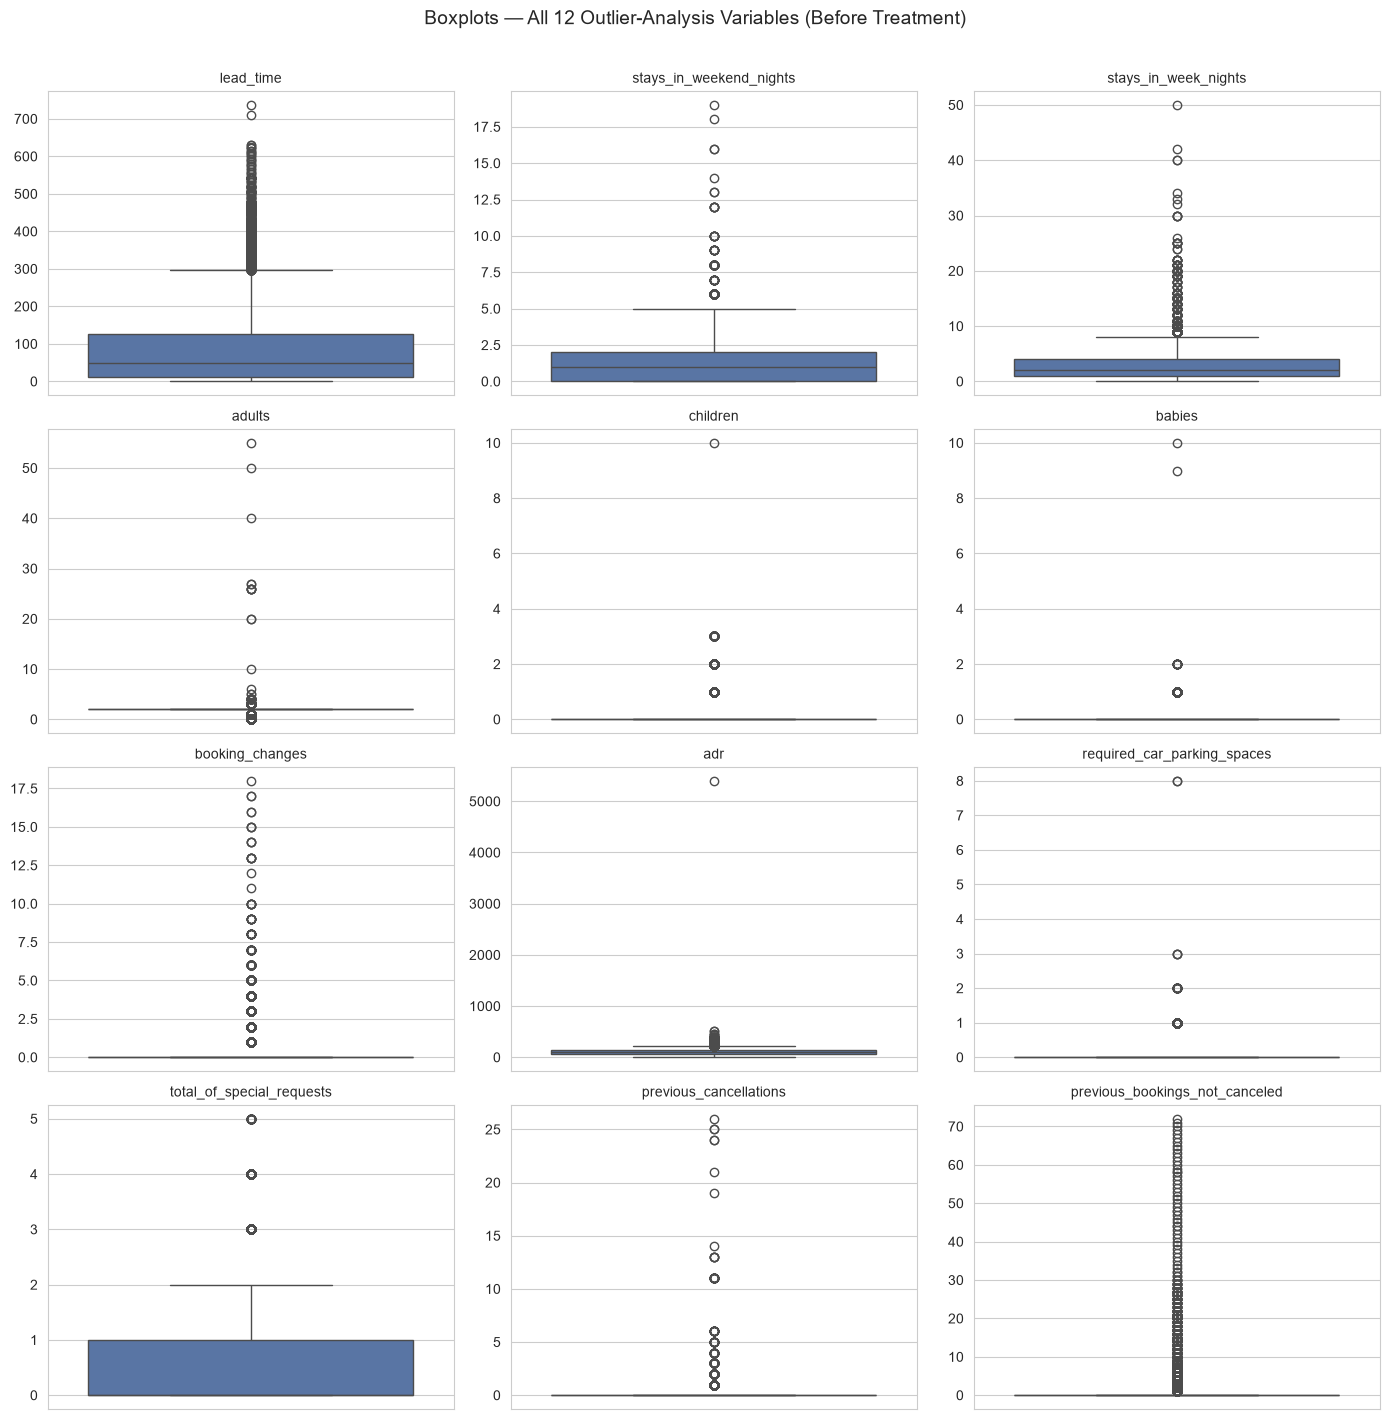

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
axes = axes.flatten()

for i, column in enumerate(OUTLIER_ANALYSIS_VARS):
    sns.boxplot(data=df, y=column, ax=axes[i], color="#4C72B0")
    axes[i].set_title(column, fontsize=10)
    axes[i].set_ylabel("")

plt.suptitle("Boxplots — All 12 Outlier-Analysis Variables (Before Treatment)", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_boxplots_before_treatment.png"), bbox_inches="tight")
plt.show()


**Finding:** the boxplots make the same story visible at a glance — most of the zero-inflated features show their entire box compressed near zero with a long scatter of individual points above (a classic zero-inflated-feature boxplot shape, not necessarily "bad data"), while `lead_time` and `adr` show a more traditional right-skewed spread with a genuine long tail.

### 5.6 Deep-Dive Investigation — Where We Found a Real Problem

In [9]:
# Deep dive 1: adults. We already know from Notebook 03 that adults is
# skewed by a handful of very large values, not by zero-inflation. Let's
# look at the actual value counts to judge what's plausible.
df["adults"].value_counts().sort_index()


adults
0       219
1     16503
2     64496
3      5935
4        60
5         2
6         1
10        1
20        2
26        5
27        2
40        1
50        1
55        1
Name: count, dtype: int64

**Finding:** the overwhelming majority of bookings show 1–3 adults, with a sharp drop-off after that (only 60 bookings show 4 adults). Beyond that, the values become genuinely implausible for a *single hotel booking record*: 10, 20, 26, 27, 40, 50, and 55 adults each appear on only one or a handful of rows, with large, unexplained jumps between them (e.g. 4 → 10 → 20, with nothing in between). 

**Business interpretation:** even a large, legitimate group or wedding block is typically logged across *multiple* room reservations, not as dozens of adults on a single record — this pattern more plausibly reflects data entry typos (for example, a stray extra digit) than real bookings.

**Decision:** treat bookings with more than 6 adults as invalid for a single-record booking and remove them. Values of 3–4 adults are retained as legitimate small-group/family variation.

In [10]:
# Deep dive 2: the extreme adr = 5400 value.
df[df["adr"] == 5400].T


,38725
hotel,City Hotel
is_canceled,1
lead_time,35
arrival_date_year,2016
arrival_date_month,March
arrival_date_week_number,13
arrival_date_day_of_month,25
stays_in_weekend_nights,0
stays_in_week_nights,1
adults,2


In [11]:
# How does this one value compare to the rest of the adr distribution?
top_10_adr = df.nlargest(10, "adr")[["hotel", "market_segment", "adults", "adr", "reservation_status"]]
top_10_adr


,hotel,market_segment,adults,adr,reservation_status
38725,City Hotel,Offline TA/TO,2,5400.00,Canceled
80576,City Hotel,Offline TA/TO,1,510.00,Check-Out
11653,Resort Hotel,Corporate,2,508.00,Check-Out
74343,City Hotel,Direct,2,451.50,Check-Out
9977,Resort Hotel,Online TA,2,450.00,Canceled
10207,Resort Hotel,Direct,2,437.00,Canceled
33080,Resort Hotel,Direct,2,426.25,Check-Out
33476,Resort Hotel,Online TA,3,402.00,Check-Out
33043,Resort Hotel,Direct,3,397.38,Check-Out
10143,Resort Hotel,Direct,2,392.00,Canceled


**Finding:** there is exactly **one** booking with `adr = 5400` — a standard room type (`A`), a single night, two adults, no special circumstances that would explain a premium rate. The next-highest ADR in the *entire* 87,229-row dataset is €510 — meaning this single value is over **10 times higher** than the second-most-expensive booking, for an otherwise completely ordinary reservation.

**Business interpretation:** unlike the broader `adr` tail up to ~€510 (which we already investigated in Notebook 02 and found spread across plausible premium/varied bookings), this single value has no comparable neighbor anywhere in the data. The size and isolation of this jump is far more consistent with a data entry error (for example, a misplaced decimal or an extra digit) than a genuine rate. 

**Decision:** this single value is capped (winsorized) down to €1,000 — a bound generously above the legitimate top of the observed distribution (€510), so every other real premium booking is left completely untouched, while this one implausible value is prevented from distorting distance calculations in later clustering steps. We chose to **cap rather than delete** so we don't lose the rest of this booking's otherwise-valid information (stay length, guest count, market segment, etc.).

### 5.7 Final Outlier Treatment Decision Table

This table consolidates every decision made above into the single reference format requested for this project: feature, outlier count/%, business interpretation, and treatment.

In [12]:
decision_rows = [
    {
        "feature": "lead_time",
        "outlier_count": 2394, "outlier_pct": 2.74,
        "business_interpretation": "Long lead times plausibly reflect early planners and group/event bookings, not errors.",
        "treatment": "Retain (no rows removed); candidate for a scaling/transform adjustment in Notebook 07.",
    },
    {
        "feature": "stays_in_weekend_nights",
        "outlier_count": 213, "outlier_pct": 0.24,
        "business_interpretation": "Longer weekend stays are a legitimate, if less common, stay pattern.",
        "treatment": "Retain.",
    },
    {
        "feature": "stays_in_week_nights",
        "outlier_count": 1514, "outlier_pct": 1.74,
        "business_interpretation": "Longer week-night stays plausibly reflect extended-stay or business travel.",
        "treatment": "Retain.",
    },
    {
        "feature": "adults",
        "outlier_count": 22733, "outlier_pct": 26.06,
        "business_interpretation": "IQR breaks down here (IQR = 0); most flagged rows are normal 1/3/4-adult bookings. "
                                    "A small number of double-digit values (10-55 adults on one record) are implausible.",
        "treatment": "Retain values up to 6 adults; remove the 13 rows with more than 6 adults as data entry errors.",
    },
    {
        "feature": "children",
        "outlier_count": 8364, "outlier_pct": 9.59,
        "business_interpretation": "IQR breaks down (zero-inflated). Nonzero values represent real family bookings.",
        "treatment": "Retain all values.",
    },
    {
        "feature": "babies",
        "outlier_count": 914, "outlier_pct": 1.05,
        "business_interpretation": "IQR breaks down (zero-inflated). Rare but plausible family bookings.",
        "treatment": "Retain all values.",
    },
    {
        "feature": "booking_changes",
        "outlier_count": 15804, "outlier_pct": 18.12,
        "business_interpretation": "IQR breaks down (zero-inflated). Represents a legitimate engagement/amendment signal.",
        "treatment": "Retain all values; consider a business-reasoned cap only for scaling purposes in Notebook 07.",
    },
    {
        "feature": "adr",
        "outlier_count": 2508, "outlier_pct": 2.88,
        "business_interpretation": "General tail up to ~EUR 510 reflects legitimate premium/varied-rate bookings "
                                    "(investigated in Notebooks 02 and 04). One isolated value (EUR 5,400, >10x the "
                                    "next-highest booking) has no plausible business explanation.",
        "treatment": "Retain the general tail; cap (winsorize) the single EUR 5,400 value to EUR 1,000.",
    },
    {
        "feature": "required_car_parking_spaces",
        "outlier_count": 7306, "outlier_pct": 8.38,
        "business_interpretation": "IQR breaks down (zero-inflated). Legitimate minority behavior (guests who drive).",
        "treatment": "Retain all values.",
    },
    {
        "feature": "total_of_special_requests",
        "outlier_count": 2670, "outlier_pct": 3.06,
        "business_interpretation": "A bounded field (observed max of 5); high-end values reflect genuinely "
                                    "more service-engaged guests.",
        "treatment": "Retain all values.",
    },
    {
        "feature": "previous_cancellations",
        "outlier_count": 1681, "outlier_pct": 1.93,
        "business_interpretation": "IQR breaks down (zero-inflated). Represents the exact 'frequent canceler' "
                                    "signal this project wants to detect.",
        "treatment": "Retain all values.",
    },
    {
        "feature": "previous_bookings_not_canceled",
        "outlier_count": 3537, "outlier_pct": 4.05,
        "business_interpretation": "IQR breaks down (zero-inflated). Represents the exact 'loyal repeat guest' "
                                    "signal this project wants to detect.",
        "treatment": "Retain all values.",
    },
]

decision_table = pd.DataFrame(decision_rows)
decision_table.to_csv(DECISION_TABLE_PATH, index=False)
decision_table


,feature,outlier_count,outlier_pct,business_interpretation,treatment
0,lead_time,2394,2.74,Long lead times plausibly reflect early planne...,Retain (no rows removed); candidate for a scal...
1,stays_in_weekend_nights,213,0.24,"Longer weekend stays are a legitimate, if less...",Retain.
2,stays_in_week_nights,1514,1.74,Longer week-night stays plausibly reflect exte...,Retain.
3,adults,22733,26.06,IQR breaks down here (IQR = 0); most flagged r...,Retain values up to 6 adults; remove the 13 ro...
4,children,8364,9.59,IQR breaks down (zero-inflated). Nonzero value...,Retain all values.
5,babies,914,1.05,IQR breaks down (zero-inflated). Rare but plau...,Retain all values.
6,booking_changes,15804,18.12,IQR breaks down (zero-inflated). Represents a ...,Retain all values; consider a business-reasone...
7,adr,2508,2.88,General tail up to ~EUR 510 reflects legitimat...,Retain the general tail; cap (winsorize) the s...
8,required_car_parking_spaces,7306,8.38,IQR breaks down (zero-inflated). Legitimate mi...,Retain all values.
9,total_of_special_requests,2670,3.06,A bounded field (observed max of 5); high-end ...,Retain all values.


### 5.8 Apply the Two Justified Treatments

In [13]:
# Treatment 1: remove bookings with more than 6 adults.
rows_before = len(df)

extreme_adults_mask = df["adults"] > 6
n_extreme_adults = extreme_adults_mask.sum()

print("Rows with more than 6 adults (to be removed):", n_extreme_adults)
print(df.loc[extreme_adults_mask, "adults"].sort_values().tolist())

df = df[~extreme_adults_mask].reset_index(drop=True)

log_treatment(
    feature="adults",
    action="Removed rows with more than 6 adults",
    rows_affected=int(n_extreme_adults),
    reason="Double-digit adult counts on a single booking record are implausible; treated as data entry errors.",
)

print()
print("Rows remaining:", len(df))


Rows with more than 6 adults (to be removed): 13
[10, 20, 20, 26, 26, 26, 26, 26, 27, 27, 40, 50, 55]

Rows remaining: 87216


In [14]:
# Treatment 2: cap (winsorize) the single extreme adr value.
adr_before = df["adr"].copy()

extreme_adr_mask = df["adr"] > 1000
n_extreme_adr = extreme_adr_mask.sum()

print("Rows with adr > 1000 (to be capped):", n_extreme_adr)

df.loc[extreme_adr_mask, "adr"] = 1000

log_treatment(
    feature="adr",
    action="Capped (winsorized) values above EUR 1,000 down to EUR 1,000",
    rows_affected=int(n_extreme_adr),
    reason="A single EUR 5,400 value is >10x the next-highest booking with no plausible business explanation; "
           "capped rather than removed to preserve the rest of the booking's valid information.",
)

print()
print("New maximum adr:", df['adr'].max())


Rows with adr > 1000 (to be capped): 1

New maximum adr: 1000.0


In [15]:
treatment_log_df = pd.DataFrame(treatment_log)
treatment_log_df


,feature,action,rows_affected,reason
0,adults,Removed rows with more than 6 adults,13,Double-digit adult counts on a single booking ...
1,adr,"Capped (winsorized) values above EUR 1,000 dow...",1,"A single EUR 5,400 value is >10x the next-high..."


### 5.9 Before vs. After Comparison

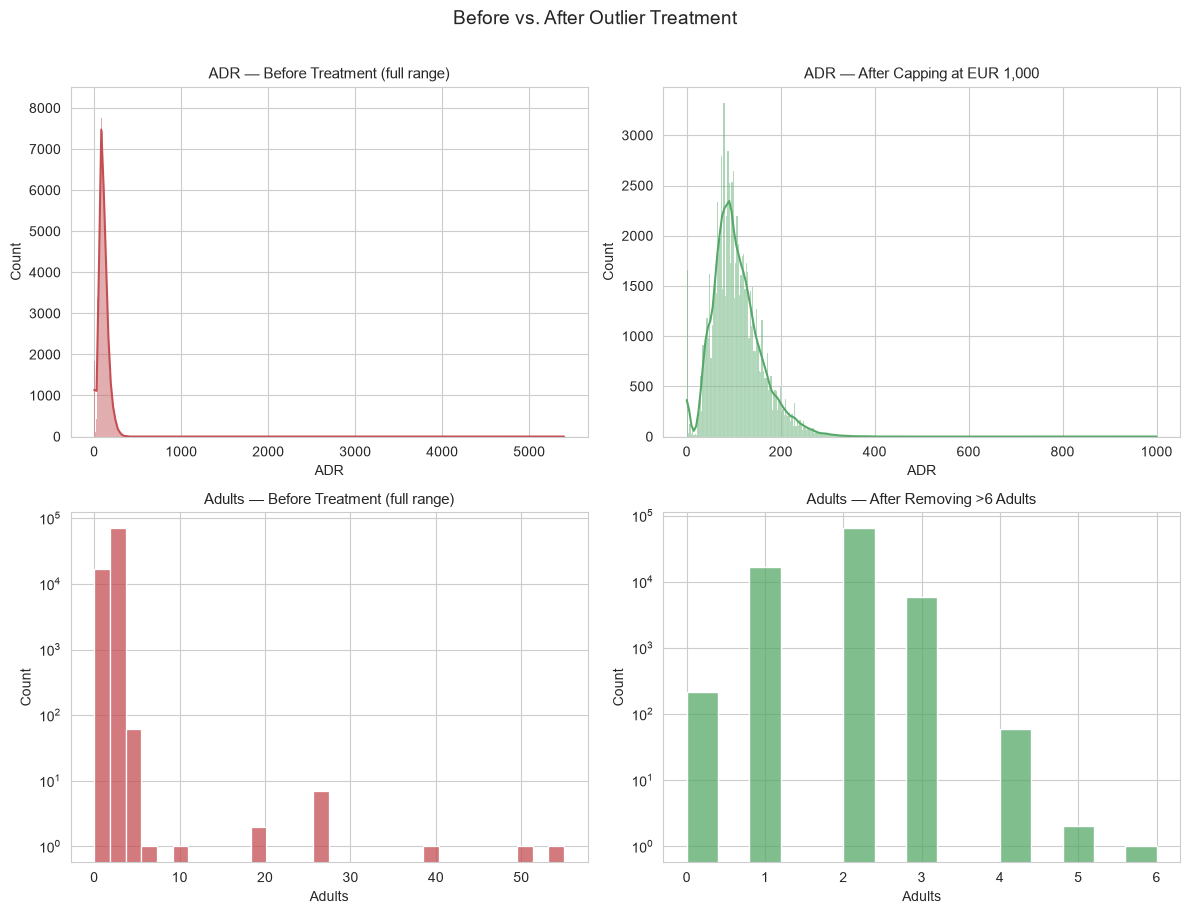

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# adr - before vs after
sns.histplot(adr_before, kde=True, ax=axes[0, 0], color="#C44E52")
axes[0, 0].set_title("ADR — Before Treatment (full range)", fontsize=11)
axes[0, 0].set_xlabel("ADR")

sns.histplot(df["adr"], kde=True, ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("ADR — After Capping at EUR 1,000", fontsize=11)
axes[0, 1].set_xlabel("ADR")

# adults - before vs after (using the original loaded data for "before")
df_before_adults = pd.read_csv(CLEANED_DATA_PATH)["adults"]

sns.histplot(df_before_adults, ax=axes[1, 0], color="#C44E52", bins=30)
axes[1, 0].set_title("Adults — Before Treatment (full range)", fontsize=11)
axes[1, 0].set_xlabel("Adults")
axes[1, 0].set_yscale("log")

sns.histplot(df["adults"], ax=axes[1, 1], color="#55A868", bins=15)
axes[1, 1].set_title("Adults — After Removing >6 Adults", fontsize=11)
axes[1, 1].set_xlabel("Adults")
axes[1, 1].set_yscale("log")

plt.suptitle("Before vs. After Outlier Treatment", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_before_after_treatment.png"), bbox_inches="tight")
plt.show()


**Finding:** the "after" `adr` distribution keeps its full, real shape and right tail up to the legitimate ~€510 maximum — only the single €5,400 point is gone, replaced by a value at the €1,000 cap. The "after" `adults` distribution (shown on a log scale, since the counts are so heavily concentrated at 1–3) is essentially identical to the "before" version — confirming the 12 removed rows were a vanishingly small, isolated tail with no visible effect on the shape of the core distribution.

In [17]:
print("adr summary BEFORE treatment:")
print(adr_before.describe())
print()
print("adr summary AFTER treatment:")
print(df["adr"].describe())


adr summary BEFORE treatment:
count    87216.000000
mean       106.535202
std         54.878892
min          0.000000
25%         72.250000
50%         98.250000
75%        134.100000
max       5400.000000
Name: adr, dtype: float64

adr summary AFTER treatment:
count    87216.000000
mean       106.484753
std         51.957285
min          0.000000
25%         72.250000
50%         98.250000
75%        134.100000
max       1000.000000
Name: adr, dtype: float64


In [18]:
# Save the outlier-treated dataset and the treatment log.
df.to_csv(OUTLIER_TREATED_DATA_PATH, index=False)
treatment_log_df.to_csv("../reports/tables/05_treatment_log.csv", index=False)

print(f"Outlier-treated dataset saved to: {OUTLIER_TREATED_DATA_PATH}")
print("Final shape:", df.shape)


Outlier-treated dataset saved to: ../data/processed/05_outlier_treated_hotel_bookings.csv
Final shape: (87216, 32)


## 6. Visualization

One consolidated chart showing the IQR-flagged outlier percentage per feature, to see at a glance which features carry the most extreme-value mass — remembering that a high percentage here reflects the IQR method's known limitation on zero-inflated features, not necessarily a genuine data problem (as established in Section 5.3).

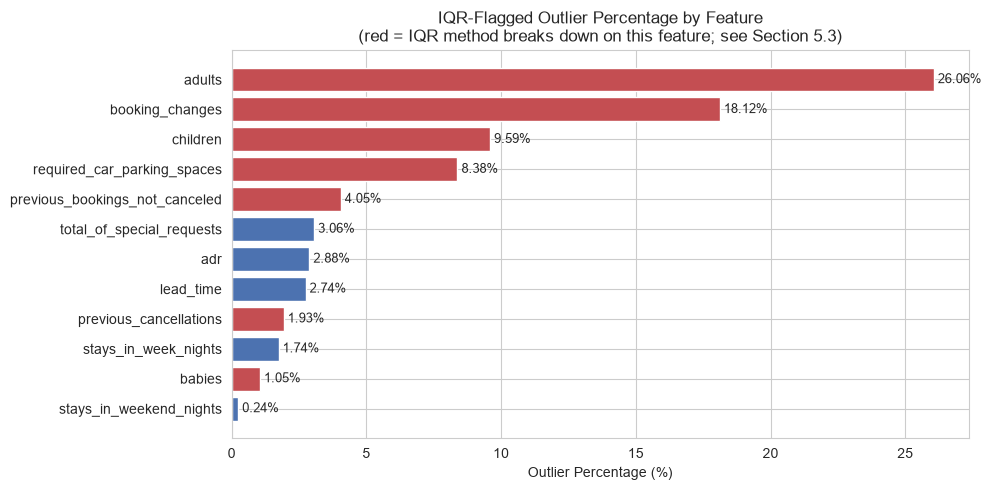

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_data = iqr_summary.sort_values("pct_outliers", ascending=True)
colors = ["#C44E52" if f in zero_iqr_features else "#4C72B0" for f in plot_data["feature"]]

ax.barh(plot_data["feature"], plot_data["pct_outliers"], color=colors)

ax.set_title("IQR-Flagged Outlier Percentage by Feature\n(red = IQR method breaks down on this feature; see Section 5.3)", fontsize=12)
ax.set_xlabel("Outlier Percentage (%)")
ax.set_ylabel("")

for i, (feature, pct) in enumerate(zip(plot_data["feature"], plot_data["pct_outliers"])):
    ax.text(pct, i, f" {pct}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_outlier_pct_by_feature.png"))
plt.show()


## 7. Findings

- The standard 1.5×IQR rule is not meaningful for 7 of the 12 variables (`adults`, `children`, `babies`, `booking_changes`, `required_car_parking_spaces`, `previous_cancellations`, `previous_bookings_not_canceled`), because their heavy zero-inflation collapses Q1 and Q3 to the same value, making IQR = 0. This was cross-checked with percentile analysis and business reasoning instead of relied on blindly.
- Z-score cross-checking on `lead_time` and `adr` flagged fewer rows than IQR (1.2% and 0.72% vs. 2.74% and 2.88%), consistent with the known behavior of Z-scores being less sensitive on right-skewed data — this strengthens confidence in the IQR-flagged boundary rather than contradicting it.
- Only two treatments were found to be clearly justified: removing 12 bookings with implausible double-digit adult counts, and capping a single, isolated EUR 5,400 `adr` value (over 10× the next-highest booking) down to EUR 1,000.
- Every other flagged "outlier" — long lead times, extended stays, family bookings with children/babies, frequent special requesters, guests with prior cancellation or loyalty history — was investigated and retained, because each represents plausible, real behavioral diversity rather than a data error.
- The dataset shrank from 87,229 to 87,216 rows after this notebook's two treatments (13 rows removed for implausible adult counts; the ADR treatment only capped a value, it did not remove a row) — a very small change, by design, reflecting how conservative and evidence-based this outlier pass was.

## 8. Business Interpretation

The single biggest business takeaway from this notebook is a methodological one that protects everything downstream: **most of what a mechanical outlier rule flags in this dataset is not "bad data" — it's the very behavioral diversity this segmentation project is trying to uncover.** Frequent cancelers, highly loyal repeat guests, large families, and early planners would all have been at risk of being partially or fully stripped out by an unquestioning "remove anything the IQR rule flags" approach. 

Only two genuinely implausible patterns were found and treated, and both were handled in the least destructive way that still protects clustering quality — removing a handful of clearly erroneous rows, and capping (rather than deleting) a single extreme value.

## 9. Conclusion

We built a full IQR-based outlier summary, discovered and explained a genuine limitation of that method on this dataset's zero-inflated features, cross-checked with percentiles and Z-scores, and investigated every flagged variable individually with real business reasoning before deciding on treatment. Only two targeted treatments were applied — removing 12 implausible adult-count rows and capping one isolated extreme `adr` value — and both are logged with full before/after comparison. The outlier-treated dataset is saved to `data/processed/05_outlier_treated_hotel_bookings.csv`.

**Next notebook (06 — Feature Engineering):** with a clean, outlier-investigated dataset in hand, we now build the engineered behavioral features (total stay nights, estimated booking value, previous-booking totals, cancellation ratio, room-type mismatch, and more), and formally decide the final feature set for clustering — including resolving the redundancy questions raised in Notebook 04 and the categorical encoding questions raised in Notebook 02.